# Proyek Analisis Data: Brazilian E-Commerce Public Dataset by Olist
- **Nama:** Bimo Priyono Pusoko
- **Email:** bimopriyonoo@gmail.com
- **ID Dicoding:** bimopriyonoo

**Tema:** E-Commerce Sales Performance and Customer Behavior Analysis

Dataset ini digunakan untuk menganalisis performa penjualan, perilaku pelanggan, dan ketepatan waktu pengiriman pada platform e-commerce Olist.

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1 — Sales Performance**

Bagaimana perkembangan total pendapatan penjualan dan jumlah pesanan setiap bulan selama periode September 2016 hingga Oktober 2018, serta kategori produk apa yang memberikan kontribusi pendapatan terbesar?

**Pertanyaan 2 — Customer Behavior**

Bagaimana karakteristik pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) selama periode transaksi September 2016 hingga Oktober 2018, serta segmen pelanggan mana yang perlu diprioritaskan dalam strategi retensi?

**Pertanyaan 3 — Delivery Performance**

Seberapa besar persentase pesanan yang terlambat diterima pelanggan dibandingkan estimasi pengiriman selama periode September 2016 hingga Oktober 2018, dan wilayah mana yang memiliki tingkat keterlambatan tertinggi?

## Import Semua Packages/Library yang Digunakan

In [1]:
# Import library
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", palette="deep")

# Menetapkan seed agar hasil proses yang membutuhkan pengacakan konsisten
RANDOM_STATE = 42

## Data Wrangling

### Gathering Data

Dataset terdiri dari sembilan file CSV. Letakkan seluruh file di dalam folder `data/raw/` pada direktori proyek. Jika menggunakan Google Colab, unggah folder tersebut atau sesuaikan variabel `DATA_DIR` dengan lokasi penyimpanan file.

In [2]:
# Menentukan lokasi dataset secara otomatis
required_files = [
    "customers_dataset.csv",
    "orders_dataset.csv",
    "order_items_dataset.csv",
    "order_payments_dataset.csv",
    "order_reviews_dataset.csv",
    "products_dataset.csv",
    "sellers_dataset.csv",
    "geolocation_dataset.csv",
    "product_category_name_translation.csv"
]

candidate_dirs = [
    Path("data/raw"),
    Path("../data/raw"),
    Path("/content/data/raw"),
    Path("/content"),
    Path("/mnt/data")
]

DATA_DIR = next(
    (folder for folder in candidate_dirs
     if all((folder / file).exists() for file in required_files)),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Sembilan file CSV belum ditemukan. Letakkan seluruh file di folder data/raw "
        "atau sesuaikan DATA_DIR."
    )

# Membaca seluruh dataset
customers_df = pd.read_csv(DATA_DIR / "customers_dataset.csv")
orders_df = pd.read_csv(DATA_DIR / "orders_dataset.csv")
order_items_df = pd.read_csv(DATA_DIR / "order_items_dataset.csv")
payments_df = pd.read_csv(DATA_DIR / "order_payments_dataset.csv")
reviews_df = pd.read_csv(DATA_DIR / "order_reviews_dataset.csv")
products_df = pd.read_csv(DATA_DIR / "products_dataset.csv")
sellers_df = pd.read_csv(DATA_DIR / "sellers_dataset.csv")
geolocation_df = pd.read_csv(DATA_DIR / "geolocation_dataset.csv")
category_df = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")

datasets = {
    "Customers": customers_df,
    "Orders": orders_df,
    "Order Items": order_items_df,
    "Payments": payments_df,
    "Reviews": reviews_df,
    "Products": products_df,
    "Sellers": sellers_df,
    "Geolocation": geolocation_df,
    "Category Translation": category_df
}

print("Seluruh dataset berhasil dimuat.")
print("Lokasi dataset:", DATA_DIR.resolve())

Seluruh dataset berhasil dimuat.
Lokasi dataset: /mnt/data/olist_submission/data/raw


**Insight:**
- Dataset berhasil dikumpulkan dari sembilan file CSV yang saling berhubungan.
- Setiap tabel memiliki fungsi berbeda, sehingga proses integrasi akan dilakukan sesuai kebutuhan analisis dan tingkat granularitas data.

### Assessing Data

Pemeriksaan kualitas data dilakukan dengan mengidentifikasi missing values, data duplikat, tipe data, dan nilai numerik yang tidak wajar. Pemeriksaan ini membantu menentukan tindakan cleaning yang tepat tanpa menghilangkan informasi yang masih valid.

In [3]:
# 1. Memeriksa ukuran dataset
overview = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Jumlah Baris": [df.shape[0] for df in datasets.values()],
    "Jumlah Kolom": [df.shape[1] for df in datasets.values()]
})
display(overview)

# 2. Memeriksa missing values
missing_summary = pd.concat(
    {name: df.isna().sum() for name, df in datasets.items()},
    axis=1
).fillna(0).astype(int)
display(missing_summary.loc[missing_summary.sum(axis=1) > 0])

# 3. Memeriksa duplicate rows
duplicate_summary = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Duplicate Rows": [df.duplicated().sum() for df in datasets.values()]
})
display(duplicate_summary)

# 4. Memeriksa tipe data
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    display(df.dtypes.astype(str).to_frame("Data Type"))

# 5. Memeriksa nilai yang tidak wajar pada kolom numerik utama
invalid_summary = pd.Series({
    "Harga produk negatif": (order_items_df["price"] < 0).sum(),
    "Freight negatif": (order_items_df["freight_value"] < 0).sum(),
    "Nilai pembayaran negatif": (payments_df["payment_value"] < 0).sum(),
    "Review score di luar 1-5": (~reviews_df["review_score"].between(1, 5)).sum(),
    "Payment installments kurang dari 1": (payments_df["payment_installments"] < 1).sum()
}, name="Jumlah")
display(invalid_summary.to_frame())

# 6. Memeriksa distribusi status pesanan
display(orders_df["order_status"].value_counts().to_frame("Jumlah Pesanan"))

# 7. Memeriksa rentang tanggal pembelian
purchase_dates = pd.to_datetime(orders_df["order_purchase_timestamp"], errors="coerce")
print("Tanggal pembelian pertama:", purchase_dates.min())
print("Tanggal pembelian terakhir:", purchase_dates.max())

,Dataset,Jumlah Baris,Jumlah Kolom
0,Customers,99441,5
1,Orders,99441,8
2,Order Items,112650,7
3,Payments,103886,5
4,Reviews,99224,7
5,Products,32951,9
6,Sellers,3095,4
7,Geolocation,1000163,5
8,Category Translation,71,2


,Customers,Orders,Order Items,Payments,Reviews,Products,Sellers,Geolocation,Category Translation
order_approved_at,0,160,0,0,0,0,0,0,0
order_delivered_carrier_date,0,1783,0,0,0,0,0,0,0
order_delivered_customer_date,0,2965,0,0,0,0,0,0,0
review_comment_title,0,0,0,0,87656,0,0,0,0
review_comment_message,0,0,0,0,58247,0,0,0,0
product_category_name,0,0,0,0,0,610,0,0,0
product_name_lenght,0,0,0,0,0,610,0,0,0
product_description_lenght,0,0,0,0,0,610,0,0,0
product_photos_qty,0,0,0,0,0,610,0,0,0
product_weight_g,0,0,0,0,0,2,0,0,0


,Dataset,Duplicate Rows
0,Customers,0
1,Orders,0
2,Order Items,0
3,Payments,0
4,Reviews,0
5,Products,0
6,Sellers,0
7,Geolocation,261831
8,Category Translation,0



===== Customers =====


,Data Type
customer_id,object
customer_unique_id,object
customer_zip_code_prefix,int64
customer_city,object
customer_state,object



===== Orders =====


... (14 outputs left out)

,Data Type
product_category_name,object
product_category_name_english,object


,Jumlah
Harga produk negatif,0
Freight negatif,0
Nilai pembayaran negatif,0
Review score di luar 1-5,0
Payment installments kurang dari 1,2


,Jumlah Pesanan
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Tanggal pembelian pertama: 2016-09-04 21:15:19
Tanggal pembelian terakhir: 2018-10-17 17:30:18


**Steps to Take:**
- Missing value pada tanggal pengiriman tidak diimputasi karena dapat menunjukkan pesanan yang belum selesai atau data pengiriman yang tidak tersedia. Analisis pengiriman hanya menggunakan pesanan berstatus `delivered` dengan tanggal aktual dan estimasi yang lengkap.
- Missing value pada komentar ulasan dipertahankan karena pelanggan dapat memberikan skor tanpa menulis komentar.
- Missing kategori produk akan diberi label `unknown` agar baris transaksi tetap dapat dipertahankan dalam agregasi produk.
- Duplikasi identik pada tabel geolocation akan dihapus. Data geolocation tidak digabungkan ke analisis utama karena analisis wilayah cukup menggunakan kode state pelanggan.
- Kolom tanggal akan dikonversi menjadi tipe datetime.
- Nilai numerik tidak valid akan diperiksa; baris hanya akan dikeluarkan dari metrik terkait jika terbukti tidak masuk akal, bukan dihapus secara membabi buta.
- Penggabungan tabel transaksi dilakukan setelah agregasi agar nilai penjualan tidak berlipat akibat relasi one-to-many.

**Insight:**
- Tabel orders memiliki missing value pada beberapa kolom tanggal persetujuan dan pengiriman.
- Tabel products memiliki kategori yang belum terisi, sedangkan tabel reviews memiliki banyak komentar kosong yang tetap dapat dianggap valid.
- Tabel geolocation memiliki baris duplikat identik sehingga perlu dibersihkan apabila tabel tersebut digunakan.

### Cleaning Data

Cleaning dilakukan berdasarkan karakteristik masing-masing kolom. Tanggal diubah menjadi datetime, duplikasi identik pada geolocation dihapus, dan kategori produk yang kosong diberi label `unknown`. Missing value pada tanggal pengiriman dan komentar ulasan tidak diimputasi karena memiliki makna bisnis tersendiri.

In [4]:
# Membuat salinan agar data mentah tetap terjaga
customers = customers_df.copy()
orders = orders_df.copy()
order_items = order_items_df.copy()
payments = payments_df.copy()
reviews = reviews_df.copy()
products = products_df.copy()
sellers = sellers_df.copy()
geolocation = geolocation_df.copy()
category_translation = category_df.copy()

# Mengubah kolom tanggal menjadi datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

for col in ["shipping_limit_date"]:
    order_items[col] = pd.to_datetime(order_items[col], errors="coerce")

for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews[col] = pd.to_datetime(reviews[col], errors="coerce")

# Menangani kategori produk kosong tanpa menghapus transaksi
products["product_category_name"] = (
    products["product_category_name"].fillna("unknown")
)

# Menghapus baris geolocation yang benar-benar identik
geolocation = geolocation.drop_duplicates().reset_index(drop=True)

# Validasi nilai numerik utama
order_items = order_items[
    (order_items["price"] >= 0) &
    (order_items["freight_value"] >= 0)
].copy()

payments = payments[payments["payment_value"] >= 0].copy()
reviews = reviews[reviews["review_score"].between(1, 5)].copy()

# Pemeriksaan hasil cleaning
cleaned_datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

cleaning_summary = pd.DataFrame({
    "Dataset": list(cleaned_datasets.keys()),
    "Rows After Cleaning": [df.shape[0] for df in cleaned_datasets.values()],
    "Missing Values": [df.isna().sum().sum() for df in cleaned_datasets.values()],
    "Duplicate Rows": [df.duplicated().sum() for df in cleaned_datasets.values()]
})
display(cleaning_summary)

,Dataset,Rows After Cleaning,Missing Values,Duplicate Rows
0,Customers,99441,0,0
1,Orders,99441,4908,0
2,Order Items,112650,0,0
3,Payments,103886,0,0
4,Reviews,99224,145903,0
5,Products,32951,1838,0
6,Sellers,3095,0,0
7,Geolocation,738332,0,0
8,Category Translation,71,0,0


**Insight:**
- Kolom tanggal telah disiapkan dalam format datetime agar dapat digunakan untuk analisis berbasis waktu.
- Missing value yang memiliki makna bisnis, seperti tanggal pengiriman dan komentar review, tetap dipertahankan.
- Kategori produk kosong ditandai sebagai `unknown`, sedangkan duplikasi identik pada geolocation dihapus.

## Exploratory Data Analysis (EDA)

EDA dilakukan untuk menjawab pertanyaan bisnis melalui agregasi dan eksplorasi data. Analisis mencakup tren penjualan bulanan, kontribusi kategori produk, segmentasi pelanggan menggunakan RFM, serta performa ketepatan waktu pengiriman berdasarkan state pelanggan.

Sebelum eksplorasi, tabel transaksi digabungkan pada tingkat yang sesuai. Item dan pembayaran diagregasikan per `order_id` terlebih dahulu agar proses merge tidak menggandakan nilai.

In [5]:
# Menambahkan nama kategori bahasa Inggris ke data produk
products_enriched = products.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="m:1"
)
products_enriched["category"] = (
    products_enriched["product_category_name_english"]
    .fillna(products_enriched["product_category_name"])
    .fillna("unknown")
)

# Menggabungkan item dengan informasi produk
items_enriched = order_items.merge(
    products_enriched[["product_id", "category"]],
    on="product_id",
    how="left",
    validate="m:1"
)

# Agregasi item pada tingkat order
order_item_agg = (
    items_enriched.groupby("order_id", as_index=False)
    .agg(
        revenue=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
)

# Agregasi pembayaran pada tingkat order
payment_agg = (
    payments.groupby("order_id", as_index=False)
    .agg(payment_total=("payment_value", "sum"))
)

# Menggabungkan orders dengan customer
orders_enriched = orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="m:1"
)

# Menggabungkan hasil agregasi agar satu baris mewakili satu order
orders_analysis = (
    orders_enriched
    .merge(order_item_agg, on="order_id", how="left", validate="1:1")
    .merge(payment_agg, on="order_id", how="left", validate="1:1")
)

# Menambahkan atribut waktu dan pengiriman
orders_analysis["order_month"] = (
    orders_analysis["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
)
orders_analysis["delivery_days"] = (
    orders_analysis["order_delivered_customer_date"] -
    orders_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_analysis["is_late"] = (
    orders_analysis["order_delivered_customer_date"] >
    orders_analysis["order_estimated_delivery_date"]
)

# Ringkasan penjualan menggunakan pesanan delivered
delivered_orders = orders_analysis[
    orders_analysis["order_status"].eq("delivered")
].copy()

monthly_sales = (
    delivered_orders.groupby("order_month", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        total_orders=("order_id", "nunique")
    )
)

category_sales = (
    items_enriched.merge(
        orders[["order_id", "order_status", "order_purchase_timestamp"]],
        on="order_id",
        how="left",
        validate="m:1"
    )
)
category_sales = category_sales[
    category_sales["order_status"].eq("delivered")
].copy()
category_sales["order_purchase_timestamp"] = pd.to_datetime(
    category_sales["order_purchase_timestamp"], errors="coerce"
)
category_sales["order_month"] = (
    category_sales["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
)
category_sales = (
    category_sales.groupby("category", as_index=False)
    .agg(revenue=("price", "sum"), items_sold=("order_item_id", "count"))
    .sort_values("revenue", ascending=False)
)

# Analisis pengiriman hanya untuk pesanan delivered dengan tanggal lengkap
delivery_analysis = delivered_orders.dropna(
    subset=["order_delivered_customer_date", "order_estimated_delivery_date"]
).copy()
delivery_by_state = (
    delivery_analysis.groupby("customer_state", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum"),
        avg_delivery_days=("delivery_days", "mean")
    )
)
delivery_by_state["late_rate"] = (
    delivery_by_state["late_orders"] / delivery_by_state["total_orders"] * 100
)
delivery_by_state = delivery_by_state.sort_values("late_rate", ascending=False)

# RFM: menggunakan pesanan delivered dan customer_unique_id
rfm_base = delivered_orders.dropna(
    subset=["customer_unique_id", "order_purchase_timestamp", "revenue"]
).copy()
reference_date = rfm_base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (
    rfm_base.groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("revenue", "sum")
    )
    .reset_index()
)
rfm["recency"] = (reference_date - rfm["last_purchase"]).dt.days

# Skor 1-5: Recency lebih kecil lebih baik, Frequency/Monetary lebih besar lebih baik
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"), 5,
    labels=[5, 4, 3, 2, 1]
).astype(int)
rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"), 5,
    labels=[1, 2, 3, 4, 5]
).astype(int)
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"), 5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

def assign_segment(row):
    r, f, m = row["R_score"], row["F_score"], row["M_score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if r >= 3 and f >= 3:
        return "Loyal Customers"
    if r >= 4 and f <= 2:
        return "Potential Loyalists"
    if r <= 2 and f >= 3:
        return "At Risk"
    if r <= 2 and f <= 2:
        return "Hibernating"
    return "Needs Attention"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

# State pelanggan untuk filter dashboard RFM (state terbanyak per customer unik)
customer_state_map = (
    customers.groupby("customer_unique_id")["customer_state"]
    .agg(lambda values: values.mode().iloc[0] if not values.mode().empty else values.iloc[0])
    .reset_index()
)
rfm = rfm.merge(customer_state_map, on="customer_unique_id", how="left", validate="1:1")

# Ringkasan eksplorasi
print("Periode transaksi:", orders["order_purchase_timestamp"].min(), "s.d.", orders["order_purchase_timestamp"].max())
print("Jumlah delivered orders:", delivered_orders["order_id"].nunique())
print("Jumlah pelanggan unik untuk RFM:", rfm["customer_unique_id"].nunique())

display(monthly_sales.head())
display(category_sales.head(10))
display(rfm.groupby("segment").agg(
    customers=("customer_unique_id", "nunique"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    total_monetary=("monetary", "sum")
).sort_values("customers", ascending=False))
display(delivery_by_state)

Periode transaksi: 2016-09-04 21:15:19 s.d. 2018-10-17 17:30:18
Jumlah delivered orders: 96478
Jumlah pelanggan unik untuk RFM: 93358


,order_month,revenue,total_orders
0,2016-09-01,134.97,1
1,2016-10-01,40325.11,265
2,2016-12-01,10.90,1
3,2017-01-01,111798.36,750
4,2017-02-01,234223.40,1653


,category,revenue,items_sold
43,health_beauty,1233131.72,9465
73,watches_gifts,1166176.98,5859
7,bed_bath_table,1023434.76,10953
67,sports_leisure,954852.55,8431
15,computers_accessories,888724.61,7644
39,furniture_decor,711927.69,8160
49,housewares,615628.69,6795
20,cool_stuff,610204.10,3718
5,auto,578966.65,4140
71,toys,471286.48,4030


,customers,avg_recency,avg_frequency,total_monetary
segment,,,,
Loyal Customers,27184,143.661529,1.034248,3059659.88
At Risk,22357,393.942703,1.048173,3209826.22
Hibernating,14986,395.508141,1.000000,2111300.53
Potential Loyalists,14984,90.878404,1.000000,2087427.21
Needs Attention,7373,220.241557,1.000000,978370.73
Champions,6474,90.894038,1.171764,1774913.54


,customer_state,total_orders,late_orders,avg_delivery_days,late_rate
1,AL,397,95,24.543855,23.929471
9,MA,717,141,21.572976,19.665272
16,PI,476,76,19.457098,15.966387
5,CE,1279,196,21.266579,15.324472
24,SE,335,51,21.519788,15.223881
4,BA,3256,457,19.335466,14.035627
18,RJ,12350,1664,15.309438,13.473684
26,TO,274,35,17.658063,12.773723
13,PA,946,117,23.772917,12.367865
7,ES,1995,244,15.789307,12.230576


**Insight:**
- Tabel analisis pesanan disusun pada tingkat satu baris per `order_id`, sehingga agregasi item dan pembayaran tidak menyebabkan penggandaan nilai.
- Analisis penjualan menggunakan pesanan berstatus `delivered` dan pendapatan produk dihitung dari penjumlahan `price`.
- RFM menggunakan `customer_unique_id` dan hanya transaksi delivered agar frekuensi serta monetary merepresentasikan pembelian yang selesai.
- Analisis keterlambatan membandingkan tanggal diterima pelanggan dengan estimasi tanggal pengiriman.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perkembangan total pendapatan penjualan dan jumlah pesanan setiap bulan, serta kategori produk apa yang memberikan kontribusi pendapatan terbesar?

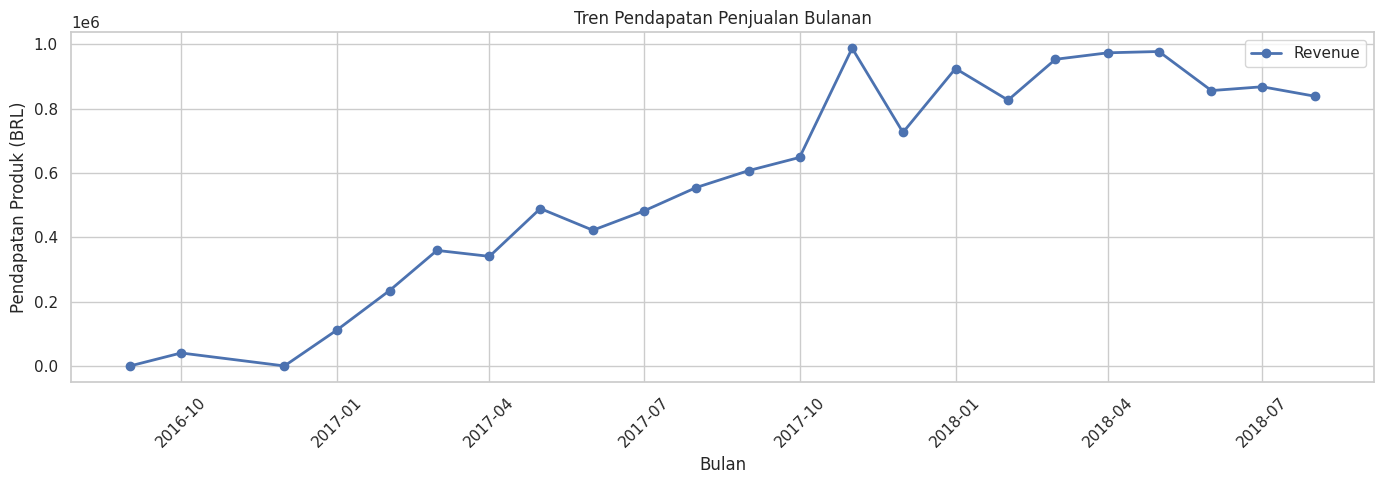

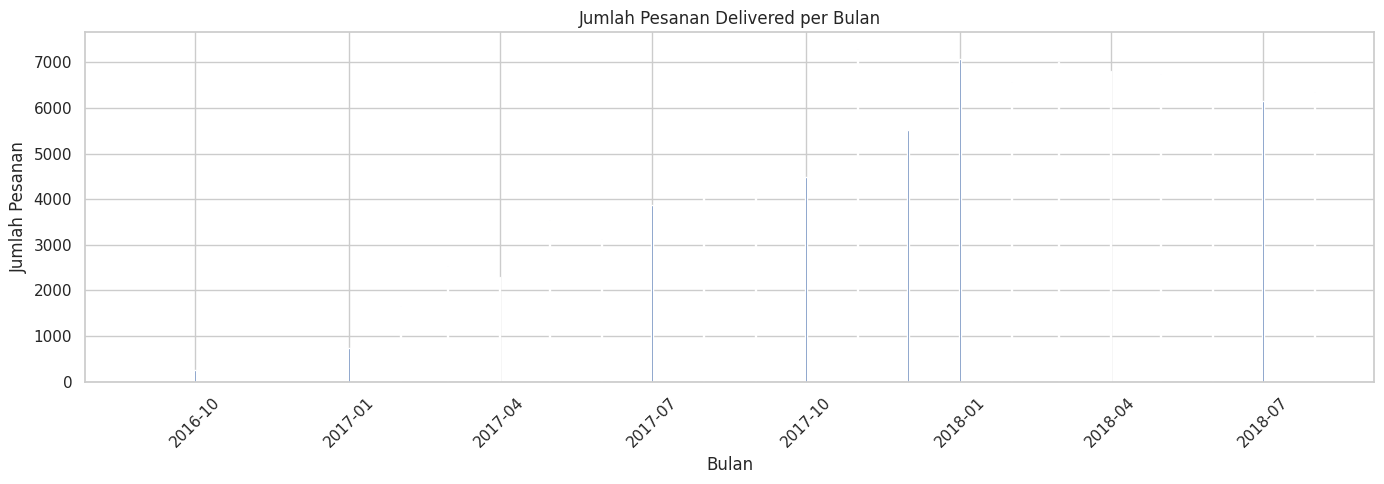

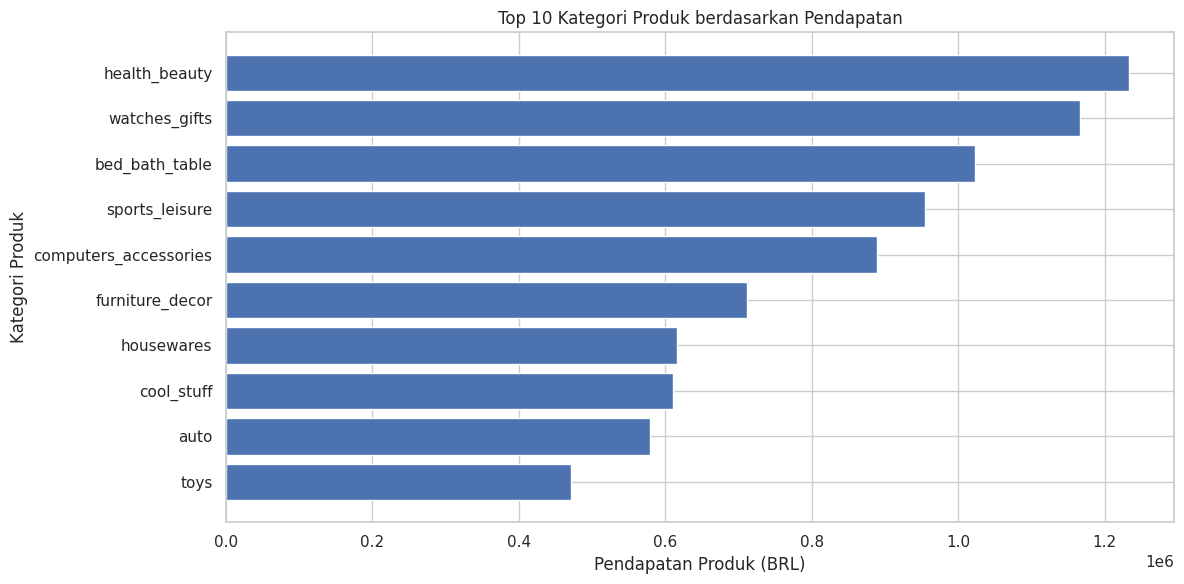

,category,revenue,items_sold
43,health_beauty,1233131.72,9465
73,watches_gifts,1166176.98,5859
7,bed_bath_table,1023434.76,10953
67,sports_leisure,954852.55,8431
15,computers_accessories,888724.61,7644
39,furniture_decor,711927.69,8160
49,housewares,615628.69,6795
20,cool_stuff,610204.10,3718
5,auto,578966.65,4140
71,toys,471286.48,4030


In [6]:
# Tren pendapatan dan jumlah pesanan bulanan
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(
    monthly_sales["order_month"], monthly_sales["revenue"],
    marker="o", linewidth=2, label="Revenue"
)
ax1.set_title("Tren Pendapatan Penjualan Bulanan")
ax1.set_xlabel("Bulan")
ax1.set_ylabel("Pendapatan Produk (BRL)")
ax1.tick_params(axis="x", rotation=45)
ax1.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(monthly_sales["order_month"], monthly_sales["total_orders"])
ax.set_title("Jumlah Pesanan Delivered per Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Pesanan")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Sepuluh kategori dengan pendapatan tertinggi
top_categories = category_sales.head(10)
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(top_categories["category"][::-1], top_categories["revenue"][::-1])
ax.set_title("Top 10 Kategori Produk berdasarkan Pendapatan")
ax.set_xlabel("Pendapatan Produk (BRL)")
ax.set_ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

display(top_categories)

### Pertanyaan 2: Bagaimana karakteristik pelanggan berdasarkan RFM dan segmen pelanggan mana yang perlu diprioritaskan dalam strategi retensi?

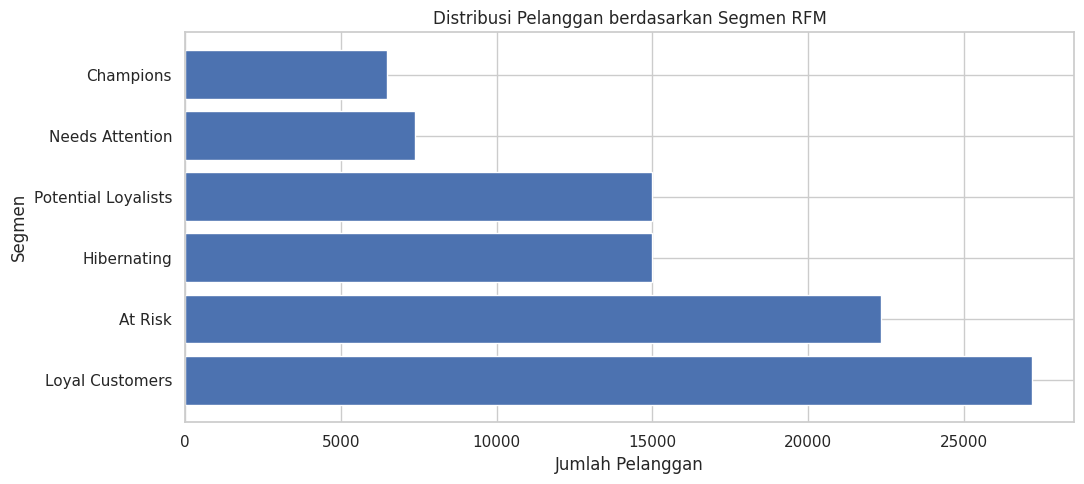

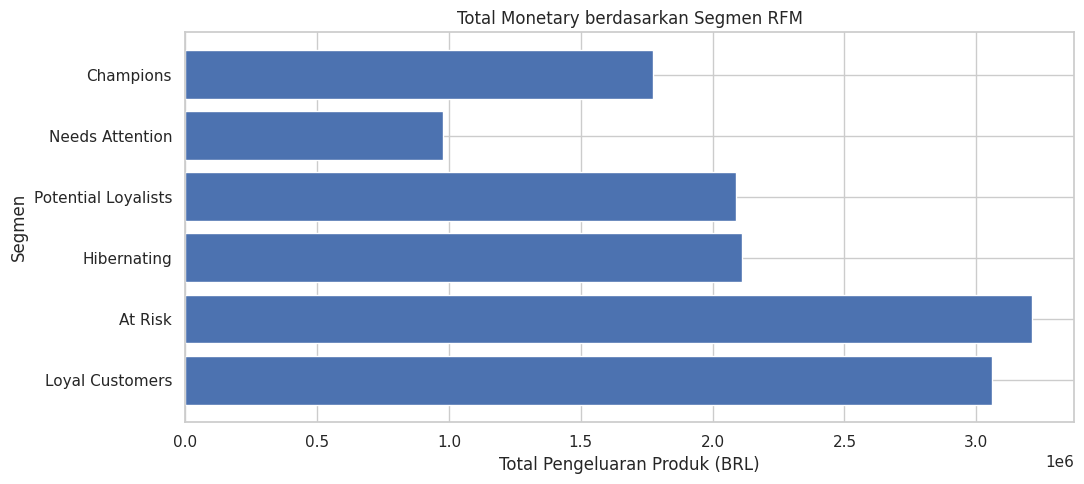

,segment,customers,avg_recency,avg_frequency,total_monetary
3,Loyal Customers,27184,143.661529,1.034248,3059659.88
0,At Risk,22357,393.942703,1.048173,3209826.22
2,Hibernating,14986,395.508141,1.000000,2111300.53
5,Potential Loyalists,14984,90.878404,1.000000,2087427.21
4,Needs Attention,7373,220.241557,1.000000,978370.73
1,Champions,6474,90.894038,1.171764,1774913.54


In [7]:
# Jumlah pelanggan pada setiap segmen RFM
segment_summary = (
    rfm.groupby("segment", as_index=False)
    .agg(
        customers=("customer_unique_id", "nunique"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        total_monetary=("monetary", "sum")
    )
    .sort_values("customers", ascending=False)
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(segment_summary["segment"], segment_summary["customers"])
ax.set_title("Distribusi Pelanggan berdasarkan Segmen RFM")
ax.set_xlabel("Jumlah Pelanggan")
ax.set_ylabel("Segmen")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(segment_summary["segment"], segment_summary["total_monetary"])
ax.set_title("Total Monetary berdasarkan Segmen RFM")
ax.set_xlabel("Total Pengeluaran Produk (BRL)")
ax.set_ylabel("Segmen")
plt.tight_layout()
plt.show()

display(segment_summary)

### Pertanyaan 3: Seberapa besar persentase pesanan yang terlambat diterima pelanggan dan wilayah mana yang memiliki tingkat keterlambatan tertinggi?


Total pesanan yang dianalisis: 96,470
Pesanan terlambat: 7,826
Tingkat keterlambatan: 8.11%


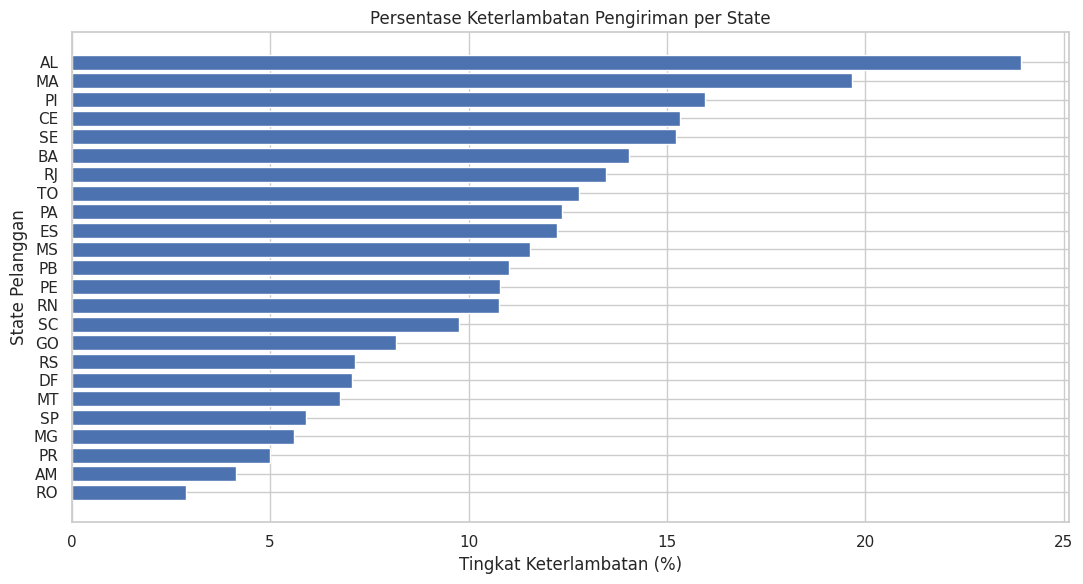

,customer_state,total_orders,late_orders,avg_delivery_days,late_rate
1,AL,397,95,24.543855,23.929471
9,MA,717,141,21.572976,19.665272
16,PI,476,76,19.457098,15.966387
5,CE,1279,196,21.266579,15.324472
24,SE,335,51,21.519788,15.223881
4,BA,3256,457,19.335466,14.035627
18,RJ,12350,1664,15.309438,13.473684
26,TO,274,35,17.658063,12.773723
13,PA,946,117,23.772917,12.367865
7,ES,1995,244,15.789307,12.230576


In [8]:

# Ringkasan ketepatan waktu pengiriman
total_delivery_orders = delivery_analysis["order_id"].nunique()
late_delivery_orders = int(delivery_analysis["is_late"].sum())
late_delivery_rate = (
    late_delivery_orders / total_delivery_orders * 100
    if total_delivery_orders else 0
)

print(f"Total pesanan yang dianalisis: {total_delivery_orders:,}")
print(f"Pesanan terlambat: {late_delivery_orders:,}")
print(f"Tingkat keterlambatan: {late_delivery_rate:.2f}%")

# Pilih state dengan jumlah order minimal 100 agar persentase lebih stabil
state_delivery_plot = delivery_by_state[
    delivery_by_state["total_orders"] >= 100
].sort_values("late_rate", ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    state_delivery_plot["customer_state"][::-1],
    state_delivery_plot["late_rate"][::-1]
)
ax.set_title("Persentase Keterlambatan Pengiriman per State")
ax.set_xlabel("Tingkat Keterlambatan (%)")
ax.set_ylabel("State Pelanggan")
plt.tight_layout()
plt.show()

display(state_delivery_plot)


**Insight:**
- Visualisasi penjualan menunjukkan pola pendapatan dan volume pesanan per bulan serta kategori yang memberikan kontribusi pendapatan terbesar.
- Visualisasi RFM memperlihatkan distribusi jumlah pelanggan dan kontribusi monetary setiap segmen.
- Analisis pengiriman mengukur persentase pesanan terlambat dan membandingkan performanya antar-state. State dengan jumlah pesanan sangat kecil perlu ditafsirkan secara hati-hati.

## Analisis Lanjutan: RFM Analysis

RFM Analysis digunakan untuk mengelompokkan pelanggan berdasarkan tiga dimensi perilaku pembelian:
- **Recency:** jumlah hari sejak transaksi terakhir pelanggan.
- **Frequency:** jumlah pesanan unik yang telah diselesaikan pelanggan.
- **Monetary:** total nilai produk yang dibeli pelanggan.

Analisis ini tidak menggunakan algoritma machine learning. Skor 1–5 dibentuk menggunakan pembagian kuantil, kemudian aturan bisnis digunakan untuk menetapkan segmen pelanggan.

,segment,customer_count,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_share_pct
0,At Risk,22357,393.942703,1.048173,143.571419,3209826.22,23.947600
3,Loyal Customers,27184,143.661529,1.034248,112.553704,3059659.88,29.118019
2,Hibernating,14986,395.508141,1.000000,140.884861,2111300.53,16.052186
5,Potential Loyalists,14984,90.878404,1.000000,139.310412,2087427.21,16.050044
1,Champions,6474,90.894038,1.171764,274.160263,1774913.54,6.934596
4,Needs Attention,7373,220.241557,1.000000,132.696423,978370.73,7.897556


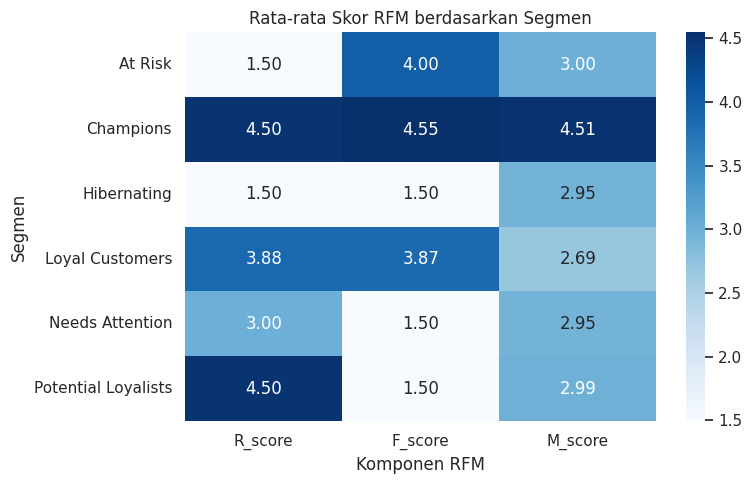

File dashboard berhasil diekspor ke folder dashboard/.


In [9]:
# Ringkasan RFM per segmen
rfm_summary = (
    rfm.groupby("segment", as_index=False)
    .agg(
        customer_count=("customer_unique_id", "nunique"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum")
    )
)

rfm_summary["customer_share_pct"] = (
    rfm_summary["customer_count"] / rfm["customer_unique_id"].nunique() * 100
)
display(rfm_summary.sort_values("total_monetary", ascending=False))

# Visualisasi heatmap rata-rata skor RFM
rfm_heatmap = rfm.groupby("segment")[["R_score", "F_score", "M_score"]].mean()
plt.figure(figsize=(8, 5))
sns.heatmap(rfm_heatmap, annot=True, cmap="Blues", fmt=".2f")
plt.title("Rata-rata Skor RFM berdasarkan Segmen")
plt.xlabel("Komponen RFM")
plt.ylabel("Segmen")
plt.tight_layout()
plt.show()

# Menyiapkan file hasil pengolahan untuk dashboard Streamlit
output_dashboard = Path("dashboard")
output_processed = Path("data/processed")
output_dashboard.mkdir(parents=True, exist_ok=True)
output_processed.mkdir(parents=True, exist_ok=True)

# Tabel utama: satu baris per order
review_agg = reviews.groupby("order_id", as_index=False).agg(
    review_score=("review_score", "mean")
)
dashboard_main = orders_analysis.merge(
    review_agg, on="order_id", how="left", validate="1:1"
)
dashboard_main.to_csv(output_dashboard / "main_data.csv", index=False)
dashboard_main.to_csv(output_processed / "orders_analysis.csv", index=False)

# Data item untuk analisis kategori dengan filter waktu dan state
dashboard_category = items_enriched.merge(
    orders[["order_id", "order_status", "order_purchase_timestamp"]],
    on="order_id", how="left", validate="m:1"
).merge(
    customers[["customer_id", "customer_state"]].merge(
        orders[["order_id", "customer_id"]],
        on="customer_id", how="left", validate="m:1"
    )[["order_id", "customer_state"]],
    on="order_id", how="left", validate="m:1"
)
dashboard_category = dashboard_category[
    dashboard_category["order_status"].eq("delivered")
].copy()
dashboard_category.to_csv(output_dashboard / "category_items.csv", index=False)
dashboard_category.to_csv(output_processed / "category_items.csv", index=False)

# Data RFM untuk halaman Customer Analytics
rfm.to_csv(output_dashboard / "rfm_data.csv", index=False)
rfm.to_csv(output_processed / "rfm_customers.csv", index=False)

print("File dashboard berhasil diekspor ke folder dashboard/.")


**Insight:**
- Segmen pelanggan dapat digunakan untuk membedakan pelanggan bernilai tinggi, pelanggan potensial, dan pelanggan yang perlu diaktifkan kembali.
- Strategi retensi sebaiknya disesuaikan dengan karakteristik setiap segmen, bukan memberikan promosi yang sama kepada seluruh pelanggan.

## Conclusion

**Kesimpulan Pertanyaan 1 — Sales Performance**

Gunakan hasil tren pendapatan bulanan dan tabel kategori untuk menyebutkan bulan dengan pendapatan tertinggi serta kategori dengan kontribusi pendapatan terbesar. Pendapatan dihitung dari nilai `price` pada item pesanan berstatus delivered, tidak termasuk freight.

**Kesimpulan Pertanyaan 2 — Customer Behavior**

Gunakan hasil RFM untuk menyebutkan segmen dengan jumlah pelanggan dan total monetary terbesar. Segmen `At Risk` dan `Hibernating` dapat menjadi perhatian program reaktivasi, sedangkan `Champions` dan `Loyal Customers` perlu dipertahankan.

**Kesimpulan Pertanyaan 3 — Delivery Performance**

Gunakan hasil perhitungan tingkat keterlambatan dan tabel per-state untuk menyebutkan tingkat keterlambatan keseluruhan serta state dengan tingkat keterlambatan tertinggi. Interpretasikan perbandingan state dengan memperhatikan jumlah pesanan.

## Recommendation

1. **Sales:** Prioritaskan ketersediaan dan promosi kategori yang memberikan kontribusi pendapatan terbesar, lalu evaluasi tren bulanan untuk perencanaan kampanye dan persediaan.
2. **Customer:** Pertahankan pelanggan Champions dan Loyal Customers melalui program loyalitas. Rancang kampanye reaktivasi khusus bagi segmen At Risk dan Hibernating.
3. **Delivery:** Evaluasi proses logistik pada state dengan tingkat keterlambatan tinggi, telusuri kapasitas mitra pengiriman, dan pantau perubahan persentase keterlambatan secara berkala.
